# L3: Interpreting TabPFN Predictions

In this lesson, you will use global and local interpretability to understand the model’s predictions at both the individual and dataset levels. You will use `TabPFNClassifier` with `fit_with_cache` on the heart-disease dataset, compute SHAP values to break down single-patient risk with waterfall plots, rank global feature importance with a beeswarm plot, and trace how continuous clinical measurements affect predicted risk using partial dependence plots.

<div style="background-color:#fff6ff; padding:13px; border-width:3px; border-color:#efe6ef; border-style:solid; border-radius:6px">


<p> ⬇ &nbsp; <b>Download Notebooks:</b> 1) click on the <em>"File"</em> option on the top menu of the notebook and then 2) click on <em>"Download"</em>.</p>
</div>

## 1. Setup


Import the interpretability helpers, configure plotting defaults, and authenticate the `tabpfn_client` session.

In [1]:
import numpy as np
from sklearn.metrics import roc_auc_score

from tabpfn_client import TabPFNClassifier

from helper import (
    CONTINUOUS,
    N_ESTIMATORS,
    RANDOM_STATE,
    categorical_indices,
    configure_lesson,
    init_tabpfn,
    load_heart_disease,
    make_shap_explainer,
    plot_beeswarm,
    plot_partial_dependence,
    plot_patient_waterfall,
    quiet_client_call,
    top_continuous_features,
)

configure_lesson(plots=True)
init_tabpfn()

## 2. Load readable data

Load the Heart Statlog dataset (200 training patients for context, 70 held out for testing) with plain-language feature names and record the categorical column indices so every explanation is easy to read.

In [2]:
X_train, X_test, y_train, y_test = load_heart_disease(
    train_size=200,
    test_size=70,
)

feature_names = list(X_train.columns)
cat_idx = categorical_indices(feature_names)

X_train.head(3)

,Age,Sex,Chest pain type,...,ST slope,Blocked vessels,Thallium scan
124,54.0,1.0,3.0,...,3.0,1.0,3.0
41,62.0,0.0,4.0,...,1.0,0.0,3.0
21,48.0,1.0,2.0,...,2.0,0.0,3.0


In [3]:
y_train.head(3)

124    0
41     0
21     0
Name: target, dtype: int64

## 3. Fit the cached model


Interpretability methods like SHAP and partial dependence evaluate the model hundreds of times on perturbed inputs. Fitting `TabPFNClassifier` with `fit_mode="fit_with_cache"` caches the training context on the server so repeated predictions don't re-encode the training table on every call.

In [4]:
clf = TabPFNClassifier(
    fit_mode="fit_with_cache",
    categorical_features_indices=cat_idx,
)
quiet_client_call(
    clf.fit, X_train.values, y_train.values
)

proba_test = quiet_client_call(
    clf.predict_proba, X_test.values
)[:, 1]
print(f"test AUC {roc_auc_score(y_test, proba_test):.3f}")

test AUC 0.915


## 4. Compute SHAP values


Build a permutation SHAP explainer using a 10-patient background sample from the training set, and compute feature attributions for the test patients. Each patient's SHAP values measure how much each clinical feature shifts their predicted heart-disease probability away from the baseline average.

In [5]:
explainer = make_shap_explainer(clf, X_train, y_train)


In [6]:
N_EXPLAIN = 10

X_explain = X_test.iloc[:N_EXPLAIN]
shap_values = explainer(
    X_explain,
    silent=False,
)
shap_values.display_data = X_explain.values

print(f"Explained {len(X_explain)} patients")

PermutationExplainer explainer: 11it [02:17, 13.70s/it]                        

Explained 10 patients


### Explaining single predictions

Because SHAP values are additive, summing a patient's feature attributions with the base value recovers their exact predicted probability. Inspect two individual cases—the highest-risk patient and a borderline patient near the 50% threshold—using waterfall plots to see which measurements push their predicted risk up or down.

In [7]:
predicted = shap_values.values.sum(axis=1) + shap_values.base_values
idx_high = int(np.argmax(predicted))
idx_borderline = int(np.argmin(np.abs(predicted - 0.5)))

[Highest-risk patient] predicted risk = 92%  (reference average 46%)
    Thallium scan      = reversible defect  raises risk by 12.0 points
    Chest pain type    = asymptomatic       raises risk by 10.7 points
    Exercise angina    = yes                raises risk by  8.1 points
    ST depression      = 3.4                raises risk by  6.2 points
    Blocked vessels    = 0                  lowers risk by  5.0 points



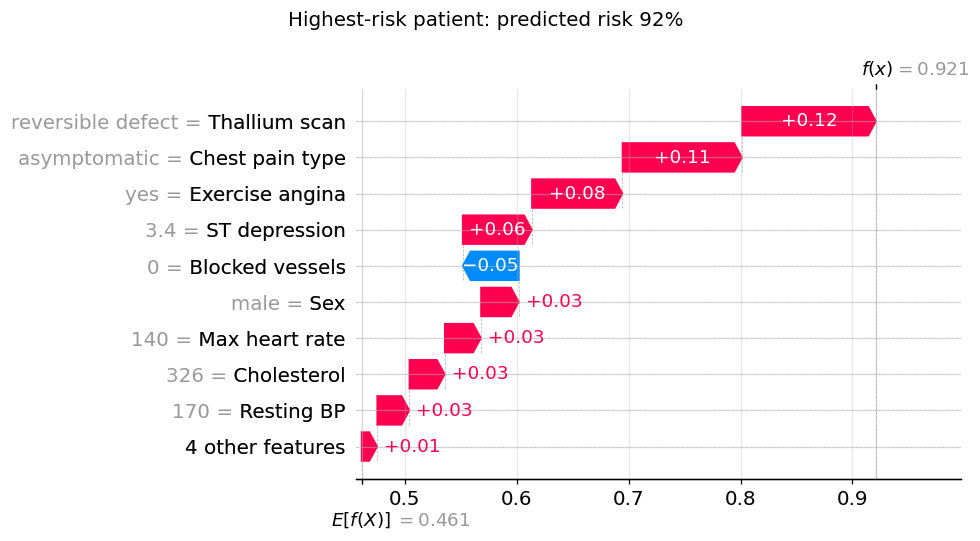

In [8]:
plot_patient_waterfall(
    shap_values, idx_high, X_explain, feature_names, "Highest-risk patient",
)

[Borderline patient] predicted risk = 69%  (reference average 46%)
    Thallium scan      = reversible defect  raises risk by 16.1 points
    Chest pain type    = asymptomatic       raises risk by 11.7 points
    ST slope           = upsloping          lowers risk by 10.0 points
    Exercise angina    = yes                raises risk by  7.9 points
    Cholesterol        = 299                raises risk by  7.3 points



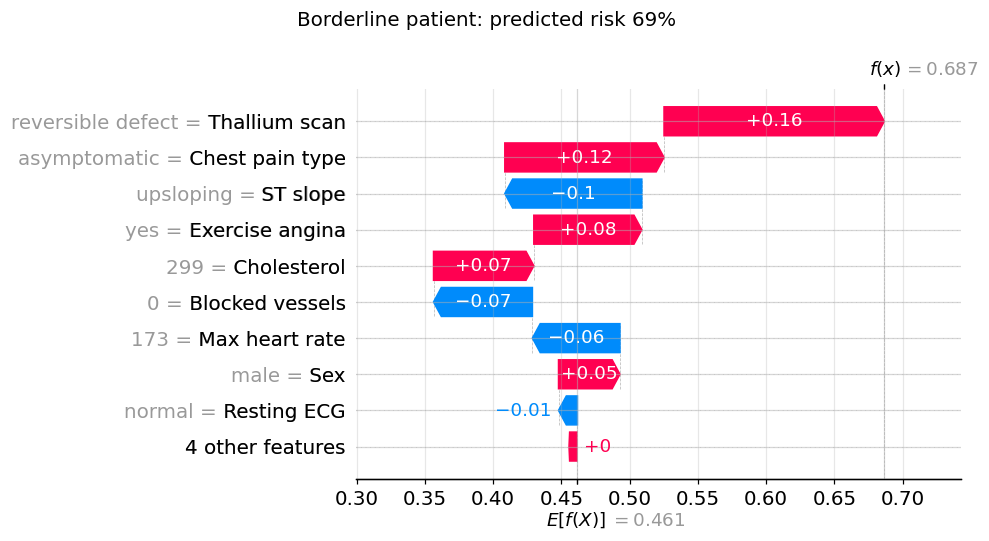

In [9]:
plot_patient_waterfall(
    shap_values, idx_borderline, X_explain, feature_names, 
    "Borderline patient",
)

## 5. Feature importance

Aggregate the SHAP values across all explained patients in a beeswarm plot. Features are ranked top-to-bottom by average absolute impact: each dot is one patient, its horizontal position shows whether that measurement pushed risk toward or away from heart disease, and its color shows whether the underlying feature value was high (red) or low (blue).

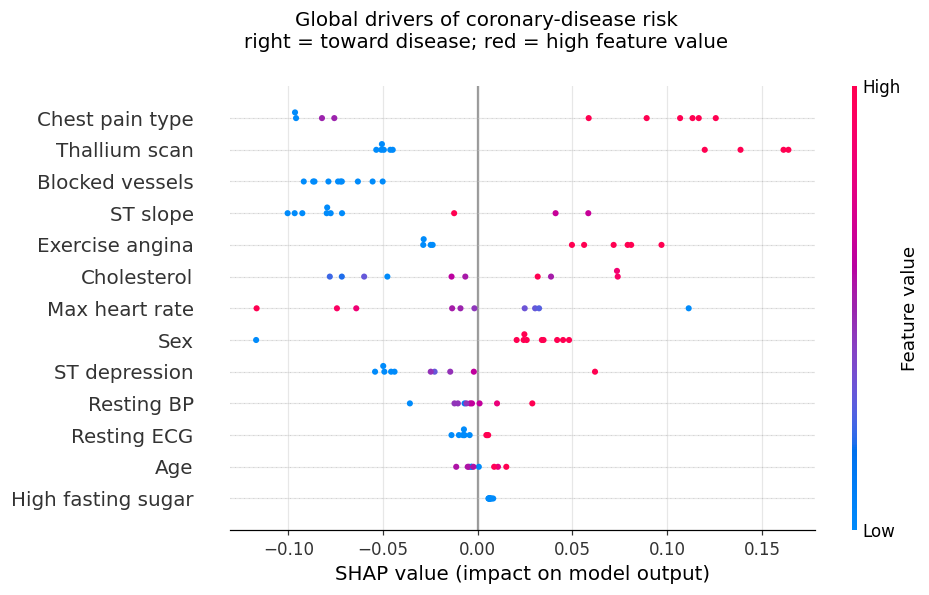

In [10]:
plot_beeswarm(shap_values, len(feature_names))

## 6. Partial dependence plots

While SHAP shows how much each feature contributed to specific predictions, partial dependence plots (PDPs) show the shape of the model's response across a feature's range. Sweep the four most impactful continuous features and plot their average predicted risk on a shared y-axis so effect sizes are directly comparable.

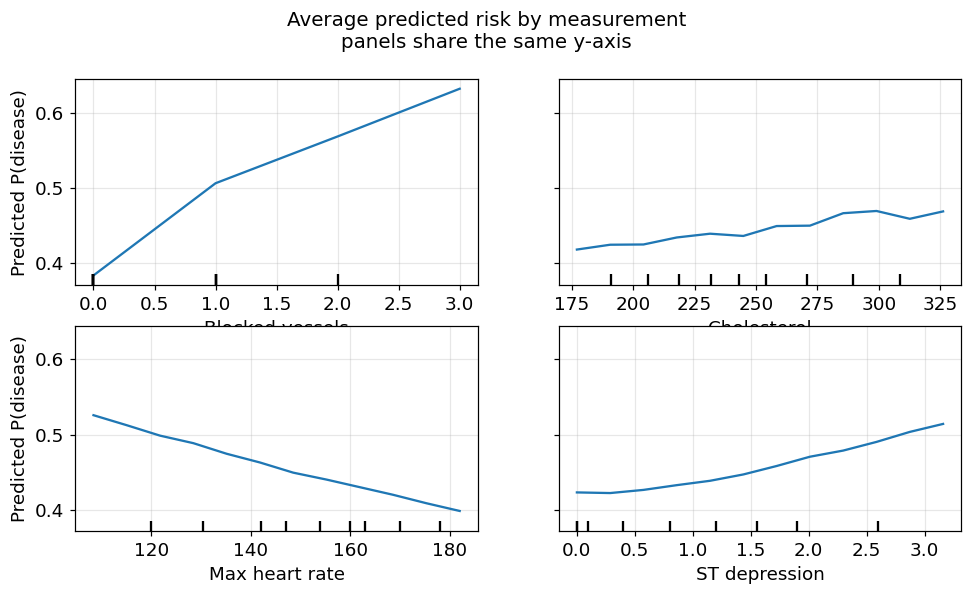

In [11]:
top_continuous = top_continuous_features(
    shap_values, feature_names, CONTINUOUS)

plot_partial_dependence(
    clf, X_train.values, top_continuous, feature_names,
)

## Recap

In this lesson, you explored three methods to interpret TabPFN predictions:

- **Individual predictions (SHAP waterfall plots):** Explain a single patient's prediction by seeing how each feature pushes their risk up or down from the baseline average.
- **Global feature importance (SHAP beeswarm plot):** Plot all SHAP values together to get a clear picture of which features have the biggest overall impact on the model's predictions.
- **Feature response curves (Partial dependence plots):** See how the model's average predicted risk responds as you vary individual continuous feature values across their range.
- **Associations, not causality:** Keep in mind that these explanations reflect statistical associations and model sensitivities in the data, not causal relationships.